# Neural Networks - Classification

In this tutorial, we will create a classification model, that predicts the value (0 to 9) from a picture with a handwritten digit.

## 0. Import python modules

We will use the Tensoflow/Keras framework for neural network machine learning.

In [2]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.datasets import mnist
from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
from plot_loss import plot_loss # own function in plot_loss.py

## 1. Load the dataset

The goal is to make a model that can recognize handwritten digits. We make use of the MNIST dataset, which is a well-known dataset of handwritten digits: https://www.tensorflow.org/datasets/catalog/mnist. The training dataset has 60000 images, the test dataset 10000. Images are grayscale and have a size of 28x28 pixels. Each pixel has a value between 0 (black) and 255 (white). The dataset is already split into train and test, so we do not have to do this ourselves. In case this is not yet done, the `train_test_split` function of `sklearn.model_selection` can be used (`from sklearn.model_selection import train_test_split`).

In [3]:
# Load the training and test dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()
# 60000 training images with 28x28 pixels
print(x_train.shape)
print(y_train.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
(60000, 28, 28)
(60000,)


x_train and x_test are 3-dimensional arrays used as input for the model. We can look at the first training image. This is a 2-dimensional array of 28 by 28. The y-values are the class the model should predict, it is a 1-dimensional array with a number 0 to 9.

In [7]:
### shape
print(f'x train: {x_train.shape} and y train: {y_train.shape}')

x train: (60000, 28, 28) and y train: (60000,)


x train: (60000, 28, 28) and y train: (60000,)
5
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0  

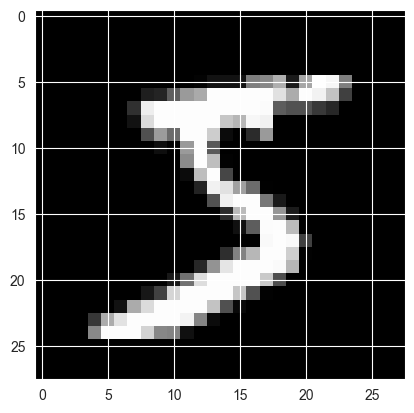

In [6]:
# y value of the first image (= class the model should predict)
print(y_train[0])
# x value (= input for the model)
print(x_train[0])
plt.imshow(x_train[0], cmap='gray', vmin=0, vmax=255)

## 2. Data transformation and normalisation

The input for our neural network with dense layers is a 2-dimensional array. The first dimension is the number of the sample. The second dimension is the number of the input node. So the 2-dimensional images need to be converted to a 1-dimensional array fitting the input layer of our model.

In [7]:
# transform the 2D-images to 1D-arrays (28 x 28 = 784)
x_train = x_train.reshape((-1, 784))   # or x_train.reshape((60000, 784))
x_test = x_test.reshape((-1, 784))
print(x_train.shape)

(60000, 784)


Now we normalize the input samples using min-max normalisation to get values between 0 and 1. We use the `MinMaxScaler` from `sklearn.preprocessing`. As we know the maximum value is 255, we could also just divide by 255.

In [8]:
# scale input
scaler = MinMaxScaler()
x_train_norm = scaler.fit_transform(x_train)
x_test_norm = scaler.transform(x_test)    # no fit, so that same scaling is used

Now we use one-hot encoding for the output. This means that the model will output 10 probabilities (probability that digit is 0, ..., probability that digit is 9). We use the `to_categorical` function from `tensorflow.keras.utils`. In case the dataset is a pandas dateframe, the `pd.get_dummies` function can be used.

In [9]:
# one-hot encoding for output
y_train_onehot = to_categorical(y_train)
y_test_onehot = to_categorical(y_test)
print(y_train_onehot.shape)
print(y_train_onehot[0])

(60000, 10)
[0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


## 3. Define the model

    ##### The input layer has 784 nodes (28 x 28). We choose 2 hidden layers with 128 and 64 nodes and a `relu` activation function (feel free to try other values/functions). The output layer has 10 nodes corresponding to the one-hot encoding vector size. The activation function of the output layer is important. As the output are 10 probabilities, the sum of them must be 1. The `softmax` activation function is enforcing this. We choose Adam as optimizer with a learning rate of `0.001`. The loss is the `categorical_crossentropy` loss which is used for classification models using one-hot encoding as output (and so used together with the `softmax` activation function). We also define a `accuracy` metric.

In [10]:
# input layer 784 nodes
inputs = Input(shape=(784,))
# 2 hidden layers
x = Dense(128, activation='relu')(inputs)
x = Dense(64, activation='relu')(x)
# output layer
outputs = Dense(10, activation='softmax')(x)
# construct the model
model = Model(inputs, outputs, name='MNIST')
# print a summary
model.summary()
# compile the model
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

Model: "MNIST"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Train the model

We train the model for 5 epochs, with a batch size of 32 (feel free to try other values). We take 10% of the training dataset for validation data.

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9274 - loss: 0.2488 - val_accuracy: 0.9662 - val_loss: 0.1204
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9673 - loss: 0.1063 - val_accuracy: 0.9758 - val_loss: 0.0898
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9776 - loss: 0.0737 - val_accuracy: 0.9790 - val_loss: 0.0763
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9819 - loss: 0.0557 - val_accuracy: 0.9743 - val_loss: 0.0902
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9865 - loss: 0.0424 - val_accuracy: 0.9750 - val_loss: 0.0938


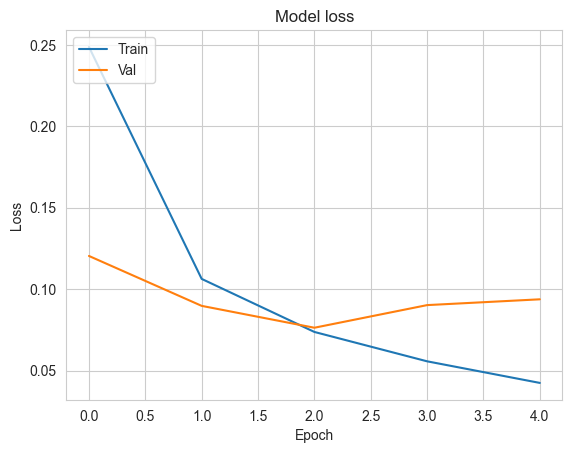

In [11]:
# train the model
history = model.fit(
    x_train_norm, # training input
    y_train_onehot, # training targets
    epochs=5,
    batch_size=32,
    validation_split=0.1,
)
# plot loss function
plot_loss(history)

## 5. Evaluate the model

Now we evaluate our model with the test data, which has not been used during training. Have a look at the accuracy score.

In [12]:
# evaluate
model.evaluate(x_test_norm,y_test_onehot)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9728 - loss: 0.0931


[0.09312326461076736, 0.9728000164031982]

## 6. Use the model to predict

We can start using the model to predict hand written digits. Here we predict the first 2 digits of the test dataset. The output of the model are probabilities. Look at the probabilities that the first digit is 7 and the second is a 2.

In [13]:
# predict 
predicted = model.predict(x_test_norm[:2])
print(predicted)
# what it should be
print(y_test[:2])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
[[5.7393077e-09 1.1123560e-06 2.1440285e-06 1.3871209e-04 5.9036714e-10
  2.1683359e-08 2.8674732e-10 9.9985695e-01 3.1565889e-08 9.5876271e-07]
 [1.3976457e-08 1.4264444e-07 9.9999821e-01 1.5925837e-06 6.6100651e-16
  1.6998025e-11 4.2738352e-10 1.3391179e-12 1.2593724e-08 3.9275406e-15]]
[7 2]
